
# 08 — Interpretabilidad de los modelos

## Taller de Análisis de Datos I — TP3

### Objetivos

1. Interpretar los coeficientes de Ridge.
2. Analizar la importancia de las variables en HGB.
3. Identificar factores asociados al error meteorológico.
4. Evaluar la reducción del sesgo residual.
5. Comparar precisión e interpretabilidad.

### Metodología

Se utilizará exclusivamente la validación histórica
del 18 de octubre al 1 de noviembre de 2026.

Los modelos utilizados para interpretación se ajustarán
con el entrenamiento histórico seguro, aplicando
preprocesamiento independiente del conjunto de validación.

No se emplearán los datos de prueba final de noviembre
ni se modificará el modelo final guardado.

La importancia de variables se interpretará como
asociación predictiva, no como evidencia causal.


In [1]:

# ==========================================
# 08 - CELDA 1
# PREPARACIÓN PARA INTERPRETABILIDAD
# ==========================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

# 1. Localizar archivos
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

carpeta = raiz / "datos_modelado"

ruta_datos = carpeta / "features_historicas_tp3.pkl.gz"
ruta_variables = carpeta / "variables_modelo_lags.json"

assert ruta_datos.is_file()
assert ruta_variables.is_file()

# 2. Cargar histórico
df_interpretabilidad = pd.read_pickle(
    ruta_datos,
    compression="gzip"
).reset_index(drop=True)

variables_interpretabilidad = json.loads(
    ruta_variables.read_text(encoding="utf-8")
)

assert len(df_interpretabilidad) == 854009
assert len(variables_interpretabilidad) == 23

# 3. Fechas
columnas_fecha = [
    "target_time_utc",
    "collection_time_utc",
    "forecast_generated_at_utc",
    "observation_collection_hour_utc"
]

for columna in columnas_fecha:
    df_interpretabilidad[columna] = pd.to_datetime(
        df_interpretabilidad[columna],
        utc=True,
        errors="coerce"
    )

assert df_interpretabilidad[columnas_fecha].notna().all().all()

# 4. Partición original
corte = pd.Timestamp("2026-10-18", tz="UTC")

train_original = df_interpretabilidad.loc[
    df_interpretabilidad["target_time_utc"] < corte
].copy()

df_val_08 = df_interpretabilidad.loc[
    df_interpretabilidad["target_time_utc"] >= corte
].copy()

# 5. Emisión efectiva de validación
primera_emision_val = df_val_08[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1).min()

# 6. Disponibilidad del error histórico
emision_train = train_original[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

observacion_disponible = (
    train_original["observation_collection_hour_utc"]
    + pd.Timedelta(hours=2)
)

disponibilidad_train = pd.concat(
    [
        emision_train.rename("emision"),
        observacion_disponible.rename("observacion")
    ],
    axis=1
).max(axis=1)

# 7. Aplicar purga
df_train_08 = train_original.loc[
    disponibilidad_train < primera_emision_val
].copy()

# 8. Auditoría
print("DATOS PARA INTERPRETABILIDAD:")
print("Histórico:", len(df_interpretabilidad))
print("Entrenamiento seguro:", len(df_train_08))
print("Validación:", len(df_val_08))
print("Características:", len(variables_interpretabilidad))

print("\nPRIMERA EMISIÓN DE VALIDACIÓN:")
print(primera_emision_val)

print("\nREGISTROS POR HORIZONTE:")

display(
    pd.DataFrame({
        "entrenamiento": (
            df_train_08["horizon_target_hours"]
            .value_counts()
        ),
        "validacion": (
            df_val_08["horizon_target_hours"]
            .value_counts()
        )
    }).sort_index()
)

# 9. Controles
assert len(df_train_08) == 659992
assert len(df_val_08) == 173583
assert len(variables_interpretabilidad) == 23

assert np.isfinite(df_train_08["error_c"]).all()
assert np.isfinite(df_val_08["error_c"]).all()

assert (
    df_interpretabilidad["target_time_utc"]
    < pd.Timestamp("2026-11-02", tz="UTC")
).all()

print("\nCONTROL FINAL:")
print("Partición histórica recuperada.")
print("Purga temporal aplicada.")
print("Datos preparados para interpretabilidad.")
print("Sin entrenamiento ni reajustes.")
print("Prueba final de noviembre no utilizada.")


DATOS PARA INTERPRETABILIDAD:
Histórico: 854009
Entrenamiento seguro: 659992
Validación: 173583
Características: 23

PRIMERA EMISIÓN DE VALIDACIÓN:
2026-10-17 00:15:05.855401+00:00

REGISTROS POR HORIZONTE:


,entrenamiento,validacion
horizon_target_hours,,
12,330000,86792
24,329992,86791



CONTROL FINAL:
Partición histórica recuperada.
Purga temporal aplicada.
Datos preparados para interpretabilidad.
Sin entrenamiento ni reajustes.
Prueba final de noviembre no utilizada.


#### Interpretabilidad del modelo Ridge
Ahora vamos a analizar qué variables utiliza Ridge para estimar el error de temperatura y en qué dirección influyen en su predicción.

Ridge es un modelo lineal. Su ventaja es que podemos examinar directamente sus coeficientes.

Por ejemplo, un coeficiente positivo indica que, manteniendo constantes las demás variables, un aumento de esa característica incrementa el error estimado:
\[
$\widehat{error}=\beta_0+\beta_1X_1+\cdots+\beta_{23}X_{23}$
\]

Recordemos que definimos el error como:
\[
$error=T_{observada}-T_{pronosticada}$
\]

Por lo tanto, un coeficiente positivo está asociado con una corrección hacia temperaturas más altas, y uno negativo, hacia temperaturas más bajas.
Qué vamos a comprobar
- Qué variables presentan los mayores coeficientes en valor absoluto.
- Cuáles se asocian con correcciones positivas o negativas.
- Qué relevancia tienen los errores históricos (lags).
- Cómo funciona Ridge sobre la validación histórica.
Importante: estandarizaremos las variables numéricas para poder comparar sus coeficientes. El indicador binario de lag faltante se analizará por separado, porque no utiliza la misma escala. Los coeficientes representan asociaciones condicionadas a las demás variables, no efectos causales.

In [2]:

# ==========================================
# 08 - CELDA 2
# INTERPRETABILIDAD DEL MODELO RIDGE
# ==========================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------
# 1. DEFINIR GRUPOS DE VARIABLES
# ------------------------------------------

variables_lag_numericas_08 = [
    "lag_error_disponible_c",
    "lag_error_edad_h"
]

variable_lag_faltante_08 = [
    "lag_error_faltante_flag"
]

variables_base_08 = [
    columna
    for columna in variables_interpretabilidad
    if columna not in (
        variables_lag_numericas_08
        + variable_lag_faltante_08
    )
]

assert len(variables_base_08) == 20
assert len(variables_lag_numericas_08) == 2
assert len(variable_lag_faltante_08) == 1

# ------------------------------------------
# 2. REPRODUCIR PREPROCESAMIENTO
# ------------------------------------------

transformacion_base_08 = Pipeline([
    (
        "imputacion",
        SimpleImputer(strategy="median")
    ),
    (
        "escalado",
        StandardScaler()
    )
])

transformacion_lags_08 = Pipeline([
    (
        "imputacion",
        SimpleImputer(
            strategy="constant",
            fill_value=0
        )
    ),
    (
        "escalado",
        StandardScaler()
    )
])

preprocesador_ridge_08 = ColumnTransformer(
    transformers=[
        (
            "variables_base",
            transformacion_base_08,
            variables_base_08
        ),
        (
            "lags_numericos",
            transformacion_lags_08,
            variables_lag_numericas_08
        ),
        (
            "lag_faltante",
            "passthrough",
            variable_lag_faltante_08
        )
    ],
    remainder="drop"
)

# ------------------------------------------
# 3. CONSTRUIR PIPELINE RIDGE
# ------------------------------------------

pipeline_ridge_08 = Pipeline([
    (
        "preprocesador",
        preprocesador_ridge_08
    ),
    (
        "modelo",
        Ridge(
            alpha=10.0,
            solver="lsqr",
            max_iter=2000,
            tol=1e-5
        )
    )
])

# ------------------------------------------
# 4. PREPARAR ENTRENAMIENTO Y VALIDACIÓN
# ------------------------------------------

X_train_08 = df_train_08[
    variables_interpretabilidad
].copy()

X_val_08 = df_val_08[
    variables_interpretabilidad
].copy()

y_train_08 = df_train_08[
    "error_c"
].to_numpy(dtype=float)

y_val_08 = df_val_08[
    "error_c"
].to_numpy(dtype=float)

# ------------------------------------------
# 5. ENTRENAR RIDGE
# ------------------------------------------

pipeline_ridge_08.fit(
    X_train_08,
    y_train_08
)

print("MODELO RIDGE ENTRENADO:")
print("Entrenamiento:", len(X_train_08))
print("Validación:", len(X_val_08))

# ------------------------------------------
# 6. EXTRAER COEFICIENTES
# ------------------------------------------

preprocesador_ajustado = (
    pipeline_ridge_08.named_steps[
        "preprocesador"
    ]
)

modelo_ajustado = (
    pipeline_ridge_08.named_steps[
        "modelo"
    ]
)

nombres_transformados = [
    nombre.split("__", 1)[-1]
    for nombre in (
        preprocesador_ajustado
        .get_feature_names_out()
    )
]

coeficientes = modelo_ajustado.coef_

assert len(nombres_transformados) == 23
assert len(coeficientes) == 23
assert set(nombres_transformados) == set(
    variables_interpretabilidad
)

df_coeficientes_ridge = pd.DataFrame({
    "variable": nombres_transformados,
    "coeficiente": coeficientes
})

df_coeficientes_ridge["valor_absoluto"] = (
    df_coeficientes_ridge[
        "coeficiente"
    ].abs()
)

df_coeficientes_ridge["tipo"] = np.where(
    df_coeficientes_ridge["variable"].eq(
        "lag_error_faltante_flag"
    ),
    "Binaria sin escalar",
    "Numérica estandarizada"
)

# ------------------------------------------
# 7. ORDENAR COEFICIENTES NUMÉRICOS
# ------------------------------------------

df_coeficientes_numericos = (
    df_coeficientes_ridge.loc[
        df_coeficientes_ridge["tipo"]
        == "Numérica estandarizada"
    ]
    .sort_values(
        "valor_absoluto",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n12 COEFICIENTES NUMÉRICOS MÁS IMPORTANTES:")

display(
    df_coeficientes_numericos.head(12).round(5)
)

# ------------------------------------------
# 8. COEFICIENTES DE LAGS
# ------------------------------------------

print("\nCOEFICIENTES DE VARIABLES HISTÓRICAS:")

display(
    df_coeficientes_ridge.loc[
        df_coeficientes_ridge["variable"].isin([
            "lag_error_disponible_c",
            "lag_error_edad_h",
            "lag_error_faltante_flag"
        ])
    ].round(5)
)

# ------------------------------------------
# 9. INTERCEPTO DEL MODELO
# ------------------------------------------

print("\nINTERCEPTO RIDGE:")
print(
    f"{modelo_ajustado.intercept_:+.5f} °C"
)

# ------------------------------------------
# 10. EVALUACIÓN HISTÓRICA
# ------------------------------------------

pred_error_ridge_08 = (
    pipeline_ridge_08.predict(X_val_08)
)

assert np.isfinite(
    pred_error_ridge_08
).all()

horizontes_08 = df_val_08[
    "horizon_target_hours"
].to_numpy()

resultados_ridge_08 = []

for horizonte in [12, 24]:

    mascara = horizontes_08 == horizonte

    real = y_val_08[mascara]
    predicho = pred_error_ridge_08[mascara]

    residual = real - predicho

    mae_original = np.mean(np.abs(real))
    mae_ridge = np.mean(np.abs(residual))

    resultados_ridge_08.append({
        "horizonte_h": horizonte,
        "registros": len(real),
        "MAE_original_c": mae_original,
        "MAE_ridge_c": mae_ridge,
        "sesgo_original_c": np.mean(real),
        "sesgo_ridge_c": np.mean(residual),
        "mejora_MAE_pct": (
            100 * (1 - mae_ridge / mae_original)
        )
    })

df_resultados_ridge_08 = pd.DataFrame(
    resultados_ridge_08
)

print("\nRESULTADOS DE RIDGE EN VALIDACIÓN:")

display(
    df_resultados_ridge_08.round(4)
)

# ------------------------------------------
# 11. CONTROLES FINALES
# ------------------------------------------

assert len(df_coeficientes_ridge) == 23

assert len(df_coeficientes_numericos) == 22

assert len(df_resultados_ridge_08) == 2

assert np.isfinite(
    df_coeficientes_ridge["coeficiente"]
).all()

assert len(pred_error_ridge_08) == 173583

print("\nCONTROL FINAL:")
print("Ridge entrenado con histórico seguro.")
print("23 coeficientes recuperados.")
print("22 variables numéricas estandarizadas.")
print("1 indicador binario analizado por separado.")
print("Resultados calculados en validación histórica.")
print("Prueba final de noviembre no utilizada.")
print("Modelo final HGB sin modificaciones.")


MODELO RIDGE ENTRENADO:
Entrenamiento: 659992
Validación: 173583

12 COEFICIENTES NUMÉRICOS MÁS IMPORTANTES:


,variable,coeficiente,valor_absoluto,tipo
0,relative_humidity_forecast_pct,1.01997,1.01997,Numérica estandarizada
1,hora_solar_sin,0.87425,0.87425,Numérica estandarizada
2,depresion_rocio_c,0.73018,0.73018,Numérica estandarizada
3,hora_utc_cos,0.40920,0.40920,Numérica estandarizada
4,dewpoint_forecast_c,-0.29787,0.29787,Numérica estandarizada
5,precip_probability_forecast_pct,-0.19917,0.19917,Numérica estandarizada
6,temperature_forecast_c,0.19764,0.19764,Numérica estandarizada
7,hora_solar_cos,-0.19068,0.19068,Numérica estandarizada
8,lag_error_disponible_c,0.15252,0.15252,Numérica estandarizada
9,wind_speed_forecast_kmh,0.14066,0.14066,Numérica estandarizada



COEFICIENTES DE VARIABLES HISTÓRICAS:


,variable,coeficiente,valor_absoluto,tipo
20,lag_error_disponible_c,0.15252,0.15252,Numérica estandarizada
21,lag_error_edad_h,-0.02380,0.02380,Numérica estandarizada
22,lag_error_faltante_flag,0.09892,0.09892,Binaria sin escalar



INTERCEPTO RIDGE:
+0.02694 °C

RESULTADOS DE RIDGE EN VALIDACIÓN:


,horizonte_h,registros,MAE_original_c,MAE_ridge_c,sesgo_original_c,sesgo_ridge_c,mejora_MAE_pct
0,12,86792,1.5636,1.5044,0.1572,-0.0256,3.7855
1,24,86791,1.5646,1.4702,0.1568,-0.0324,6.0335



CONTROL FINAL:
Ridge entrenado con histórico seguro.
23 coeficientes recuperados.
22 variables numéricas estandarizadas.
1 indicador binario analizado por separado.
Resultados calculados en validación histórica.
Prueba final de noviembre no utilizada.
Modelo final HGB sin modificaciones.


#### Interpretación de los coeficientes de Ridge

1. ¿Qué variables tienen mayor peso?

| Variable |	Coeficiente |	Interpretación |
|----------|----------------|------------------|
| Humedad relativa |	+1,01997 |	Asociación positiva con el error estimado |
| Hora solar (seno) |	+0,87425 |	Influencia del ciclo horario solar |
| Depresión del punto de rocío |	+0,73018 |	Relación con las condiciones de humedad |
| Hora UTC (coseno) |	+0,40920 |	Influencia del ciclo horario UTC |
| Temperatura de rocío |	−0,29787 |	Asociación negativa con el error estimado |
| Error histórico disponible |	+0,15252 |	El error anterior aporta información predictiva |

Hay tres hallazgos relevantes:
- La humedad aparece como un factor importante. Tanto la humedad relativa como la depresión del punto de rocío presentan coeficientes elevados.
- La hora del día importa. Las variables cíclicas solares y UTC aparecen entre las de mayor magnitud.
- Los errores históricos aportan información. El coeficiente positivo del error anterior indica que Ridge utiliza parte del comportamiento reciente para estimar la siguiente corrección.
Una aclaración metodológica: estas variables pueden estar correlacionadas entre sí. Por ejemplo, humedad relativa, temperatura y punto de rocío están relacionados. Por eso, un coeficiente grande no demuestra que esa variable sea individualmente la causa del error. Además, los coeficientes de seno y coseno describen ciclos, no incrementos lineales de horas.
2. ¿Ridge consiguió corregir el sesgo?
Sí, en esta partición de validación.

| Horizonte |	Sesgo original |	Sesgo Ridge |	Mejora MAE |
|-----------|------------------|----------------|-----------|
| 12 horas |	+0,1572 °C |	−0,0256 °C |	+3,79 % |
| 24 horas |	+0,1568 °C |	−0,0324 °C |	+6,03 % |

Ridge redujo considerablemente el sesgo medio, aunque produjo una pequeña sobrecorrección hacia valores negativos.

Esto complementa lo observado en la validación cruzada: Ridge funcionó bien en este período particular, pero mostró resultados menos estables en los cuatro folds anteriores.

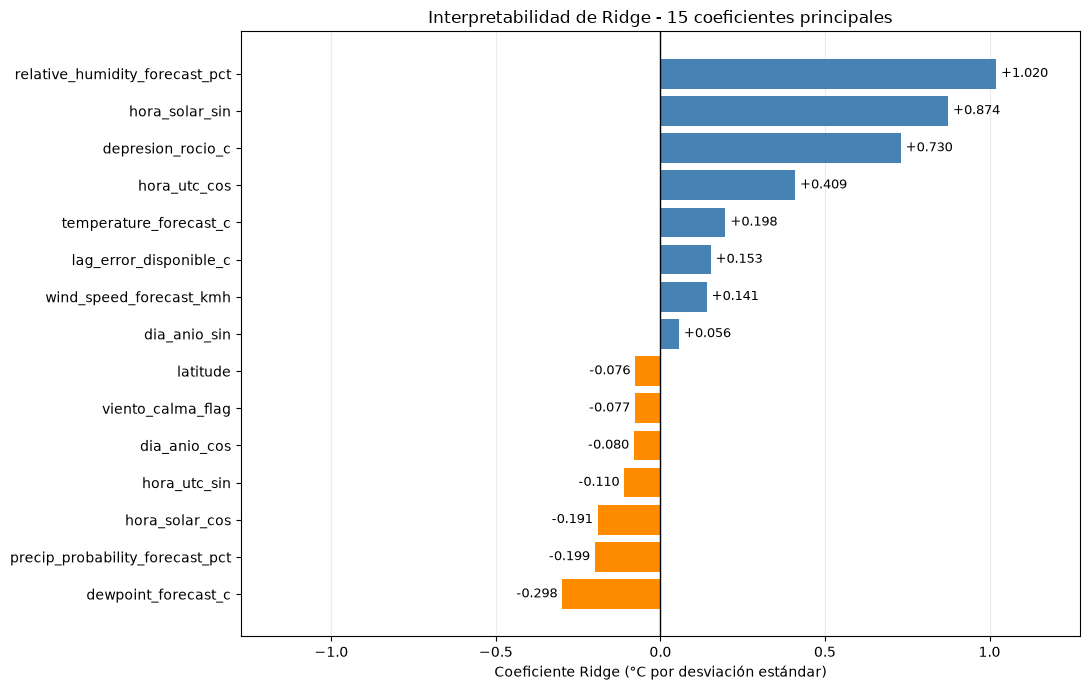

VARIABLES HISTÓRICAS:


,variable,coeficiente,valor_absoluto,tipo
20,lag_error_disponible_c,0.15252,0.15252,Numérica estandarizada
21,lag_error_edad_h,-0.02380,0.02380,Numérica estandarizada
22,lag_error_faltante_flag,0.09892,0.09892,Binaria sin escalar



ARCHIVOS GENERADOS:
01_coeficientes_ridge.png - 105055 bytes
02_coeficientes_ridge_completos.csv - 1939 bytes
03_metricas_ridge_validacion.csv - 314 bytes

CONTROL FINAL:
15 coeficientes principales representados.
23 coeficientes originales exportados.
Métricas históricas Ridge exportadas.
Indicador binario separado del gráfico.
No se entrenaron nuevos modelos.
Prueba final de noviembre no utilizada.


In [3]:

# ==========================================
# 08 - CELDA 3
# VISUALIZACIÓN DE COEFICIENTES RIDGE
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. SELECCIONAR COEFICIENTES NUMÉRICOS
# ------------------------------------------

# El indicador binario se excluye del gráfico
# principal porque no está estandarizado.

df_grafico_ridge = (
    df_coeficientes_numericos
    .head(15)
    .sort_values("coeficiente")
    .copy()
)

assert len(df_grafico_ridge) == 15
assert df_grafico_ridge["variable"].is_unique

# ------------------------------------------
# 2. IDENTIFICAR DIRECCIÓN DEL COEFICIENTE
# ------------------------------------------

colores = np.where(
    df_grafico_ridge["coeficiente"] >= 0,
    "steelblue",
    "darkorange"
)

# ------------------------------------------
# 3. CREAR GRÁFICO
# ------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

barras = ax.barh(
    df_grafico_ridge["variable"],
    df_grafico_ridge["coeficiente"],
    color=colores
)

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.set_xlabel(
    "Coeficiente Ridge (°C por desviación estándar)"
)

ax.set_title(
    "Interpretabilidad de Ridge - 15 coeficientes principales"
)

ax.grid(
    axis="x",
    alpha=0.25
)

ax.set_axisbelow(True)

# Agregar etiquetas numéricas
for barra, valor in zip(
    barras,
    df_grafico_ridge["coeficiente"]
):

    posicion = barra.get_width()

    desplazamiento = (
        0.015 if valor >= 0 else -0.015
    )

    ax.text(
        posicion + desplazamiento,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:+.3f}",
        va="center",
        ha="left" if valor >= 0 else "right",
        fontsize=9
    )

limite = max(
    abs(df_grafico_ridge["coeficiente"].min()),
    abs(df_grafico_ridge["coeficiente"].max())
)

ax.set_xlim(
    -limite * 1.25,
    limite * 1.25
)

fig.tight_layout()

# ------------------------------------------
# 4. EXPORTAR GRÁFICO Y TABLAS
# ------------------------------------------

carpeta_interpretabilidad = (
    raiz / "resultados_ml" / "interpretabilidad"
)

carpeta_interpretabilidad.mkdir(
    parents=True,
    exist_ok=True
)

ruta_grafico = (
    carpeta_interpretabilidad
    / "01_coeficientes_ridge.png"
)

fig.savefig(
    ruta_grafico,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

df_coeficientes_ridge.to_csv(
    carpeta_interpretabilidad
    / "02_coeficientes_ridge_completos.csv",
    index=False,
    encoding="utf-8-sig"
)

df_resultados_ridge_08.to_csv(
    carpeta_interpretabilidad
    / "03_metricas_ridge_validacion.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------
# 5. ANALIZAR VARIABLES HISTÓRICAS
# ------------------------------------------

print("VARIABLES HISTÓRICAS:")

display(
    df_coeficientes_ridge.loc[
        df_coeficientes_ridge["variable"].isin([
            "lag_error_disponible_c",
            "lag_error_edad_h",
            "lag_error_faltante_flag"
        ])
    ].round(5)
)

# ------------------------------------------
# 6. CONTROL FINAL
# ------------------------------------------

assert ruta_grafico.is_file()

assert len(df_coeficientes_ridge) == 23

assert (
    df_coeficientes_ridge["variable"]
    .is_unique
)

print("\nARCHIVOS GENERADOS:")

for archivo in sorted(
    carpeta_interpretabilidad.iterdir()
):
    if archivo.is_file():
        print(
            archivo.name,
            "-",
            archivo.stat().st_size,
            "bytes"
        )

print("\nCONTROL FINAL:")
print("15 coeficientes principales representados.")
print("23 coeficientes originales exportados.")
print("Métricas históricas Ridge exportadas.")
print("Indicador binario separado del gráfico.")
print("No se entrenaron nuevos modelos.")
print("Prueba final de noviembre no utilizada.")


#### Interpretación del gráfico
El gráfico nos permite identificar tres grupos de variables relevantes:
- Humedad y punto de rocío: la humedad relativa (+1,020) y la depresión del punto de rocío (+0,730) presentan coeficientes positivos importantes. La temperatura de rocío tiene un coeficiente negativo (−0,298).
- Ciclos horarios: la hora solar y la hora UTC aparecen entre los principales coeficientes. Esto sugiere que el error depende, en parte, del momento del día.
- Errores históricos: lag_error_disponible_c presenta un coeficiente positivo (+0,153). Ridge aprovecha información de errores anteriores para calcular sus correcciones.
Una precisión para el informe: estos coeficientes corresponden a características estandarizadas, incluidas algunas variables binarias. Por eso describen asociaciones dentro del modelo, pero no debemos interpretarlos como efectos causales ni considerar que cada variable actúa independientemente.

HGB ENTRENADO PARA INTERPRETABILIDAD
Entrenamiento: 659992
Características: 23

RESULTADOS HGB EN VALIDACIÓN:


,horizonte_h,registros,MAE_original_c,MAE_hgb_c,RMSE_hgb_c,sesgo_hgb_c,mejora_MAE_pct
0,12,86792,1.5636,1.4369,1.8336,-0.0432,8.1016
1,24,86791,1.5646,1.4353,1.8273,-0.0359,8.2673



MUESTRA PARA PERMUTACIÓN:
Registros: 10000

15 VARIABLES CON MAYOR IMPORTANCIA:


,variable,incremento_MAE_c,desviacion_repeticiones_c
0,hora_solar_cos,0.09514,0.00218
1,wind_speed_forecast_kmh,0.07768,0.00092
2,hora_solar_sin,0.04690,0.00246
3,precip_probability_forecast_pct,0.02404,0.00079
4,hora_utc_cos,0.02210,0.00129
5,latitude,0.00989,0.00099
6,dia_anio_sin,0.00944,0.00069
7,lag_error_disponible_c,0.00907,0.00050
8,relative_humidity_forecast_pct,0.00466,0.00077
9,longitude,0.00312,0.00034


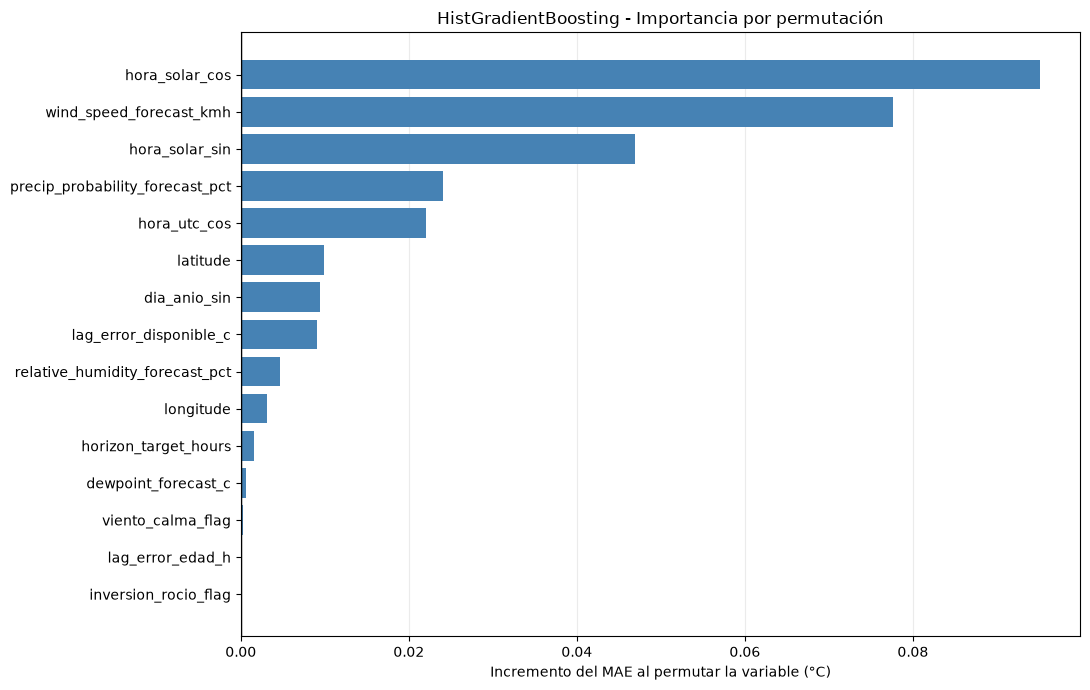


CONTROL FINAL:
HGB entrenado solo con histórico seguro.
Validación histórica evaluada.
23 características analizadas.
Permutación realizada con 3 repeticiones.
Importancias y métricas exportadas.
Prueba final de noviembre no utilizada.
Modelo final guardado sin modificaciones.


In [4]:

# ==========================================
# 08 - CELDA 4
# IMPORTANCIA POR PERMUTACIÓN - HGB
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

# ------------------------------------------
# 1. PREPROCESADOR INDEPENDIENTE
# ------------------------------------------

# Reutilizamos la configuración de Ridge,
# pero ajustamos una copia desde cero.

preprocesador_hgb_08 = clone(
    preprocesador_ridge_08
)

X_train_hgb_pre = (
    preprocesador_hgb_08
    .fit_transform(X_train_08)
    .astype("float32")
)

X_val_hgb_pre = (
    preprocesador_hgb_08
    .transform(X_val_08)
    .astype("float32")
)

assert X_train_hgb_pre.shape == (659992, 23)
assert X_val_hgb_pre.shape == (173583, 23)

assert np.isfinite(X_train_hgb_pre).all()
assert np.isfinite(X_val_hgb_pre).all()

# ------------------------------------------
# 2. ENTRENAR HGB CON PARÁMETROS FIJOS
# ------------------------------------------

modelo_hgb_08 = HistGradientBoostingRegressor(
    loss="squared_error",
    learning_rate=0.07,
    max_iter=120,
    max_leaf_nodes=15,
    max_depth=6,
    min_samples_leaf=80,
    l2_regularization=10.0,
    early_stopping=False,
    random_state=42
)

modelo_hgb_08.fit(
    X_train_hgb_pre,
    y_train_08
)

print("HGB ENTRENADO PARA INTERPRETABILIDAD")
print("Entrenamiento:", len(y_train_08))
print("Características:", X_train_hgb_pre.shape[1])

# ------------------------------------------
# 3. VERIFICAR MÉTRICAS DE VALIDACIÓN
# ------------------------------------------

pred_hgb_08 = modelo_hgb_08.predict(
    X_val_hgb_pre
)

resultados_hgb_08 = []

for horizonte in [12, 24]:

    mascara = horizontes_08 == horizonte

    error_real = y_val_08[mascara]
    correccion = pred_hgb_08[mascara]

    residual = error_real - correccion

    mae_original = np.abs(error_real).mean()
    mae_hgb = np.abs(residual).mean()

    resultados_hgb_08.append({
        "horizonte_h": horizonte,
        "registros": int(mascara.sum()),
        "MAE_original_c": mae_original,
        "MAE_hgb_c": mae_hgb,
        "RMSE_hgb_c": np.sqrt(
            np.mean(residual ** 2)
        ),
        "sesgo_hgb_c": residual.mean(),
        "mejora_MAE_pct": (
            100 * (1 - mae_hgb / mae_original)
        )
    })

df_resultados_hgb_08 = pd.DataFrame(
    resultados_hgb_08
)

print("\nRESULTADOS HGB EN VALIDACIÓN:")
display(df_resultados_hgb_08.round(4))

# ------------------------------------------
# 4. SELECCIONAR MUESTRA EQUILIBRADA
# ------------------------------------------

# Hasta 500 registros por día y horizonte.
# Muestreo reproducible, sin alterar datos.

grupos = df_val_08.groupby(
    [
        df_val_08["target_time_utc"].dt.date,
        "horizon_target_hours"
    ],
    sort=True
)

indices_muestra = np.concatenate([
    grupo.sample(
        n=min(500, len(grupo)),
        random_state=42
    ).index.to_numpy()
    for _, grupo in grupos
])

X_muestra = X_val_08.loc[indices_muestra]

y_muestra = df_val_08.loc[
    indices_muestra, "error_c"
].to_numpy(dtype=float)

X_muestra_pre = (
    preprocesador_hgb_08
    .transform(X_muestra)
    .astype("float32")
)

assert len(indices_muestra) > 0
assert len(np.unique(indices_muestra)) == len(indices_muestra)
assert np.isfinite(X_muestra_pre).all()

print("\nMUESTRA PARA PERMUTACIÓN:")
print("Registros:", len(indices_muestra))

# ------------------------------------------
# 5. IMPORTANCIA POR PERMUTACIÓN
# ------------------------------------------

# Scoring = MAE negativo.
# Una importancia positiva representa
# cuánto aumenta el MAE al permutar.

importancias_hgb = permutation_importance(
    modelo_hgb_08,
    X_muestra_pre,
    y_muestra,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

# ------------------------------------------
# 6. RECUPERAR NOMBRES DE VARIABLES
# ------------------------------------------

nombres_hgb = [
    nombre.split("__", 1)[-1]
    for nombre in (
        preprocesador_hgb_08
        .get_feature_names_out()
    )
]

assert len(nombres_hgb) == 23
assert set(nombres_hgb) == set(
    variables_interpretabilidad
)

df_importancia_hgb_08 = pd.DataFrame({
    "variable": nombres_hgb,
    "incremento_MAE_c": (
        importancias_hgb.importances_mean
    ),
    "desviacion_repeticiones_c": (
        importancias_hgb.importances_std
    )
}).sort_values(
    "incremento_MAE_c",
    ascending=False
).reset_index(drop=True)

print("\n15 VARIABLES CON MAYOR IMPORTANCIA:")

display(
    df_importancia_hgb_08.head(15).round(5)
)

# ------------------------------------------
# 7. GRÁFICO DE LAS 15 PRINCIPALES
# ------------------------------------------

df_grafico_hgb = (
    df_importancia_hgb_08
    .head(15)
    .sort_values("incremento_MAE_c")
)

fig, ax = plt.subplots(figsize=(11, 7))

colores = np.where(
    df_grafico_hgb["incremento_MAE_c"] >= 0,
    "steelblue",
    "darkorange"
)

ax.barh(
    df_grafico_hgb["variable"],
    df_grafico_hgb["incremento_MAE_c"],
    color=colores
)

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.set_xlabel(
    "Incremento del MAE al permutar la variable (°C)"
)

ax.set_title(
    "HistGradientBoosting - Importancia por permutación"
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()

# ------------------------------------------
# 8. EXPORTAR
# ------------------------------------------

carpeta_interpretabilidad = (
    raiz / "resultados_ml" / "interpretabilidad"
)

carpeta_interpretabilidad.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    carpeta_interpretabilidad
    / "04_importancia_permutacion_hgb.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

df_importancia_hgb_08.to_csv(
    carpeta_interpretabilidad
    / "05_importancia_hgb.csv",
    index=False,
    encoding="utf-8-sig"
)

df_resultados_hgb_08.to_csv(
    carpeta_interpretabilidad
    / "06_metricas_hgb_validacion.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------
# 9. CONTROLES FINALES
# ------------------------------------------

assert len(df_importancia_hgb_08) == 23
assert len(df_resultados_hgb_08) == 2

assert np.isfinite(
    df_importancia_hgb_08["incremento_MAE_c"]
).all()

print("\nCONTROL FINAL:")
print("HGB entrenado solo con histórico seguro.")
print("Validación histórica evaluada.")
print("23 características analizadas.")
print("Permutación realizada con 3 repeticiones.")
print("Importancias y métricas exportadas.")
print("Prueba final de noviembre no utilizada.")
print("Modelo final guardado sin modificaciones.")


#### Interpretación de HistGradientBoosting


Interpretabilidad de HGB completada

Mejora MAE · 12 horas
8,10 %

Mejora MAE · 24 horas
8,27 %



Variables de mayor importancia
Variable	Aumento del MAE al permutar
Hora solar (coseno)	+0,09514 °C
Velocidad del viento	+0,07768 °C
Hora solar (seno)	+0,04690 °C
Probabilidad de precipitación	+0,02404 °C
Hora UTC (coseno)	+0,02210 °C
Error histórico disponible	+0,00907 °C

El gráfico muestra tres hallazgos:

1. El ciclo solar es especialmente relevante. Las dos componentes de la hora solar aparecen entre los tres primeros puestos. Esto sugiere que el momento del día, expresado en relación con la ubicación de cada estación, contiene información útil para corregir los errores.

2. El viento y la precipitación aportan información. La velocidad del viento ocupa el segundo lugar, mientras que la probabilidad de precipitación también presenta una contribución predictiva apreciable.

3. Los errores históricos ayudan, pero no dominan el modelo. lag_error_disponible_c ocupa el octavo puesto. Su importancia positiva indica que alterar esa característica perjudica la precisión de HGB.
Comparación con Ridge
En Ridge, la humedad relativa aparece como la variable de mayor coeficiente estandarizado. En HGB, en cambio, adquieren mayor protagonismo el ciclo solar y la velocidad del viento.

Esto es compatible con las diferencias entre ambos algoritmos:
- Ridge: representa relaciones lineales entre los predictores transformados y el error.
- HGB: puede representar relaciones no lineales e interacciones.

MÉTRICAS Y SESGOS POR HORIZONTE:


,horizonte_h,registros,MAE_original_c,sesgo_original_c,MAE_ridge_c,sesgo_ridge_c,MAE_hgb_c,sesgo_hgb_c
0,12,86792,1.5636,0.1572,1.5044,-0.0256,1.4369,-0.0432
1,24,86791,1.5646,0.1568,1.4702,-0.0324,1.4353,-0.0359
2,Global,173583,1.5641,0.1570,1.4873,-0.0290,1.4361,-0.0396



SESGO DIARIO POR HORIZONTE:


,fecha,horizon_target_hours,registros,sesgo_original_c,sesgo_ridge_c,sesgo_hgb_c
0,2026-10-18,12,9999,0.4573,0.3872,0.0943
1,2026-10-18,24,9999,0.5378,0.4802,0.1905
2,2026-10-19,12,8077,-0.2494,-0.3856,-0.4354
3,2026-10-19,24,8077,-0.0967,-0.2139,-0.2541
4,2026-10-20,12,8196,0.0390,-0.2099,-0.1359
5,2026-10-20,24,8196,-0.0306,-0.2625,-0.2360
6,2026-10-21,12,9677,0.0634,-0.0163,-0.0233
7,2026-10-21,24,9677,-0.0606,-0.1473,-0.1552
8,2026-10-27,12,6287,0.3952,0.1794,0.1695
9,2026-10-27,24,6287,0.3548,0.1070,0.1212



ESTABILIDAD DEL SESGO RESIDUAL:


,horizonte_h,dias_evaluados,ridge_reduce_sesgo_dias,hgb_reduce_sesgo_dias
0,12,10,6,6
1,24,10,6,6


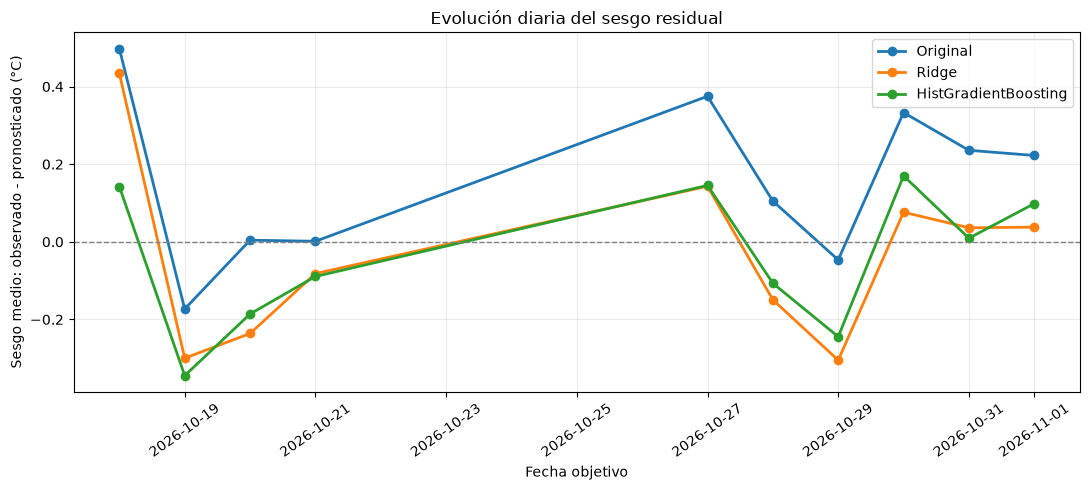


CONTROL FINAL:
Sesgo original, Ridge y HGB comparados.
Análisis realizado por horizonte y fecha.
20 combinaciones de fecha y horizonte.
Resultados y gráfico exportados.
No se entrenaron nuevos modelos.
Prueba final de noviembre no utilizada.
Modelo final guardado sin modificaciones.


In [5]:

# ==========================================
# 08 - CELDA 5
# ANÁLISIS DEL SESGO RESIDUAL
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. PREPARAR ERRORES RESIDUALES
# ------------------------------------------

df_residuales_08 = df_val_08[
    [
        "target_time_utc",
        "horizon_target_hours",
        "error_c"
    ]
].copy().reset_index(drop=True)

df_residuales_08["fecha"] = (
    df_residuales_08["target_time_utc"].dt.date
)

df_residuales_08["error_original_c"] = (
    y_val_08
)

df_residuales_08["error_ridge_c"] = (
    y_val_08 - pred_error_ridge_08
)

df_residuales_08["error_hgb_c"] = (
    y_val_08 - pred_hgb_08
)

columnas_error = [
    "error_original_c",
    "error_ridge_c",
    "error_hgb_c"
]

assert len(df_residuales_08) == 173583

assert np.isfinite(
    df_residuales_08[columnas_error]
    .to_numpy(dtype=float)
).all()

# ------------------------------------------
# 2. COMPARACIÓN POR HORIZONTE Y GLOBAL
# ------------------------------------------

resultados_sesgo = []

for horizonte in [12, 24, "Global"]:

    if horizonte == "Global":
        datos = df_residuales_08
    else:
        datos = df_residuales_08.loc[
            df_residuales_08[
                "horizon_target_hours"
            ] == horizonte
        ]

    fila = {
        "horizonte_h": horizonte,
        "registros": len(datos)
    }

    for nombre, columna in [
        ("original", "error_original_c"),
        ("ridge", "error_ridge_c"),
        ("hgb", "error_hgb_c")
    ]:

        errores = datos[columna].to_numpy()

        fila[f"MAE_{nombre}_c"] = (
            np.abs(errores).mean()
        )

        fila[f"sesgo_{nombre}_c"] = (
            errores.mean()
        )

    resultados_sesgo.append(fila)

df_resumen_sesgo_08 = pd.DataFrame(
    resultados_sesgo
)

print("MÉTRICAS Y SESGOS POR HORIZONTE:")

display(
    df_resumen_sesgo_08.round(4)
)

# ------------------------------------------
# 3. SESGO DIARIO POR HORIZONTE
# ------------------------------------------

df_sesgo_diario_08 = (
    df_residuales_08
    .groupby(
        ["fecha", "horizon_target_hours"],
        as_index=False
    )
    .agg(
        registros=("error_original_c", "size"),
        sesgo_original_c=("error_original_c", "mean"),
        sesgo_ridge_c=("error_ridge_c", "mean"),
        sesgo_hgb_c=("error_hgb_c", "mean")
    )
)

print("\nSESGO DIARIO POR HORIZONTE:")

display(
    df_sesgo_diario_08.round(4)
)

# ------------------------------------------
# 4. ¿CUÁNTOS DÍAS REDUJERON EL SESGO?
# ------------------------------------------

estabilidad_sesgo = []

for horizonte in [12, 24]:

    datos = df_sesgo_diario_08.loc[
        df_sesgo_diario_08[
            "horizon_target_hours"
        ] == horizonte
    ]

    sesgo_original = np.abs(
        datos["sesgo_original_c"]
    )

    estabilidad_sesgo.append({
        "horizonte_h": horizonte,
        "dias_evaluados": len(datos),
        "ridge_reduce_sesgo_dias": int(
            (
                np.abs(datos["sesgo_ridge_c"])
                < sesgo_original
            ).sum()
        ),
        "hgb_reduce_sesgo_dias": int(
            (
                np.abs(datos["sesgo_hgb_c"])
                < sesgo_original
            ).sum()
        )
    })

df_estabilidad_sesgo_08 = pd.DataFrame(
    estabilidad_sesgo
)

print("\nESTABILIDAD DEL SESGO RESIDUAL:")

display(df_estabilidad_sesgo_08)

# ------------------------------------------
# 5. EVOLUCIÓN DIARIA DEL SESGO GLOBAL
# ------------------------------------------

df_sesgo_global_diario_08 = (
    df_residuales_08
    .groupby("fecha")[columnas_error]
    .mean()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(11, 5))

for columna, etiqueta in [
    ("error_original_c", "Original"),
    ("error_ridge_c", "Ridge"),
    ("error_hgb_c", "HistGradientBoosting")
]:

    ax.plot(
        df_sesgo_global_diario_08.index,
        df_sesgo_global_diario_08[columna],
        marker="o",
        linewidth=2,
        label=etiqueta
    )

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1,
    color="gray"
)

ax.set_title(
    "Evolución diaria del sesgo residual"
)

ax.set_xlabel("Fecha objetivo")
ax.set_ylabel(
    "Sesgo medio: observado - pronosticado (°C)"
)

ax.tick_params(
    axis="x",
    rotation=35
)

ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

# ------------------------------------------
# 6. EXPORTAR
# ------------------------------------------

carpeta_interpretabilidad.mkdir(
    parents=True,
    exist_ok=True
)

df_resumen_sesgo_08.to_csv(
    carpeta_interpretabilidad
    / "07_resumen_sesgos.csv",
    index=False,
    encoding="utf-8-sig"
)

df_sesgo_diario_08.to_csv(
    carpeta_interpretabilidad
    / "08_sesgos_diarios.csv",
    index=False,
    encoding="utf-8-sig"
)

df_estabilidad_sesgo_08.to_csv(
    carpeta_interpretabilidad
    / "09_estabilidad_sesgo.csv",
    index=False,
    encoding="utf-8-sig"
)

fig.savefig(
    carpeta_interpretabilidad
    / "10_evolucion_sesgo_residual.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------
# 7. CONTROLES FINALES
# ------------------------------------------

assert len(df_resumen_sesgo_08) == 3
assert len(df_sesgo_diario_08) == 20
assert len(df_estabilidad_sesgo_08) == 2

assert (
    df_resumen_sesgo_08.loc[
        df_resumen_sesgo_08["horizonte_h"]
        == "Global",
        "registros"
    ].iloc[0] == 173583
)

print("\nCONTROL FINAL:")
print("Sesgo original, Ridge y HGB comparados.")
print("Análisis realizado por horizonte y fecha.")
print("20 combinaciones de fecha y horizonte.")
print("Resultados y gráfico exportados.")
print("No se entrenaron nuevos modelos.")
print("Prueba final de noviembre no utilizada.")
print("Modelo final guardado sin modificaciones.")


Indicador global	Original	Ridge	HGB
MAE	1,5641 °C	1,4873 °C	1,4361 °C
Sesgo medio	+0,1570 °C	−0,0290 °C	−0,0396 °C
Días con reducción del sesgo, 12 h	—	6/10	6/10
Días con reducción del sesgo, 24 h	—	6/10	6/10

Los resultados demuestran que:
1. HGB logra mayor precisión global, al conseguir el MAE más bajo.
2. Ridge consigue un sesgo medio ligeramente más cercano a cero, aunque su error absoluto es mayor.
3. Ninguno corrige mejor el sesgo todos los días. Ambos reducen su magnitud en 6 de los 10 días evaluados para cada horizonte.
Por ejemplo, el 19 de octubre ambos modelos aumentaron la magnitud del sesgo original. En cambio, el 27 de octubre ambos la redujeron considerablemente.

Esto es importante para la presentación: reducir el MAE no garantiza eliminar sistemáticamente el sesgo diario.

Una pequeña corrección estética del gráfico
El gráfico que compartiste está bien, pero detecté un detalle: conecta el 21 de octubre con el 27 de octubre mediante una línea continua.

Como excluimos los días 22 al 26 por problemas de calidad, conviene representar ese intervalo como un espacio sin información, en lugar de conectar ambos extremos.

Vamos a corregirlo sin recalcular modelos ni modificar las métricas.

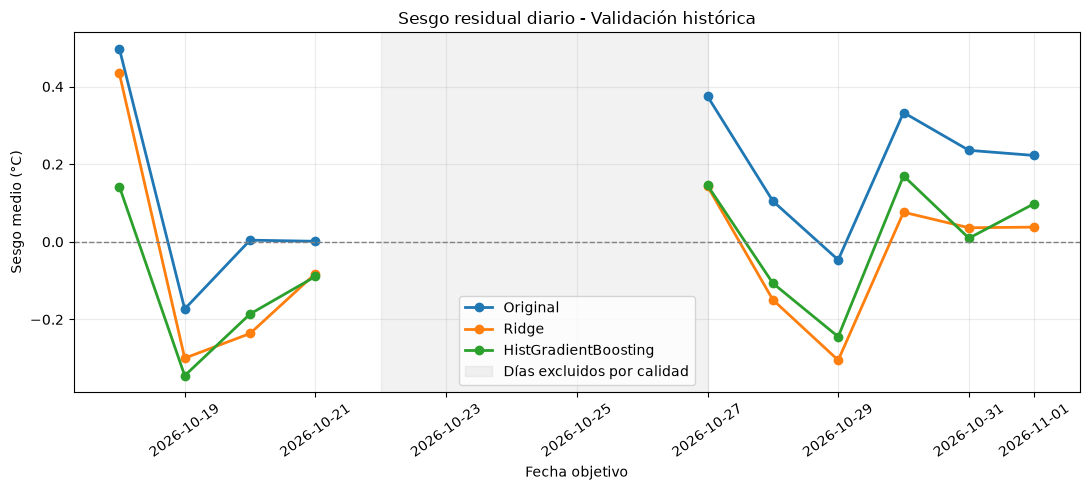

CONTROL FINAL:
Gráfico corregido correctamente.
Días 22-26 de octubre señalados.
No se interpolaron observaciones.
No se modificaron métricas.
No se reentrenaron modelos.
Notebook 08 listo para cierre.


In [6]:

# ==========================================
# 08 - CELDA 6
# GRÁFICO FINAL SIN INTERPOLAR DÍAS EXCLUIDOS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Recuperar resultados diarios existentes
df_grafico_final = (
    df_sesgo_global_diario_08.copy()
)

df_grafico_final.index = pd.to_datetime(
    df_grafico_final.index
)

# 2. Incluir todas las fechas del intervalo
# Los días excluidos permanecerán como NaN
fechas_completas = pd.date_range(
    "2026-10-18",
    "2026-11-01",
    freq="D"
)

df_grafico_final = df_grafico_final.reindex(
    fechas_completas
)

# 3. Comprobar días excluidos
fechas_excluidas = pd.date_range(
    "2026-10-22",
    "2026-10-26",
    freq="D"
)

assert df_grafico_final.loc[
    fechas_excluidas
].isna().all().all()

assert df_grafico_final.dropna().shape[0] == 10

# 4. Crear gráfico definitivo
fig, ax = plt.subplots(figsize=(11, 5))

series = [
    ("error_original_c", "Original"),
    ("error_ridge_c", "Ridge"),
    ("error_hgb_c", "HistGradientBoosting")
]

for columna, etiqueta in series:
    ax.plot(
        df_grafico_final.index,
        df_grafico_final[columna],
        marker="o",
        linewidth=2,
        label=etiqueta
    )

ax.axhline(
    0,
    linestyle="--",
    color="gray",
    linewidth=1
)

ax.axvspan(
    pd.Timestamp("2026-10-22"),
    pd.Timestamp("2026-10-27"),
    color="gray",
    alpha=0.10,
    label="Días excluidos por calidad"
)

ax.set_title(
    "Sesgo residual diario - Validación histórica"
)

ax.set_xlabel("Fecha objetivo")
ax.set_ylabel("Sesgo medio (°C)")

ax.legend()
ax.grid(alpha=0.25)

ax.tick_params(axis="x", rotation=35)

fig.tight_layout()

# 5. Reemplazar solamente el gráfico anterior
ruta_grafico_final = (
    carpeta_interpretabilidad
    / "10_evolucion_sesgo_residual.png"
)

fig.savefig(
    ruta_grafico_final,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# 6. Controles finales
assert ruta_grafico_final.is_file()

print("CONTROL FINAL:")
print("Gráfico corregido correctamente.")
print("Días 22-26 de octubre señalados.")
print("No se interpolaron observaciones.")
print("No se modificaron métricas.")
print("No se reentrenaron modelos.")
print("Notebook 08 listo para cierre.")
